In [2]:
import scanpy as sc
import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [4]:
all_data = ad.read_h5ad("processed_annotated.h5ad")

e:\mdx single cell and nuclei\.venv\Lib\site-packages\anndata\_core\anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [5]:
YAP_targets = pd.read_excel("YAP target genes.xlsx", sheet_name=1)

In [6]:
sc.tl.score_genes(all_data, gene_list=YAP_targets["lower"].tolist(), score_name="YAP_score")

In [7]:
from sklearn.preprocessing import MinMaxScaler

# Extract scores
scores = all_data.obs['YAP_score'].values.reshape(-1, 1)

# Scale to 0-1
scaler = MinMaxScaler()
all_data.obs['YAP_score_scaled'] = scaler.fit_transform(scores)

In [37]:
cell_labels = all_data.obs['cell_type'].unique().tolist()

In [ ]:
print(cell_labels)

['Type 2b', 'Type 2a/x', 'MTJ', 'ECs', 'FAPs', 'Smooth muscle', 'Immune cells', 'SCs', 'NMJ', 'Tenocyotes', 'Adipocytes', 'Schwann cells', 'Regenerating myonuclei']


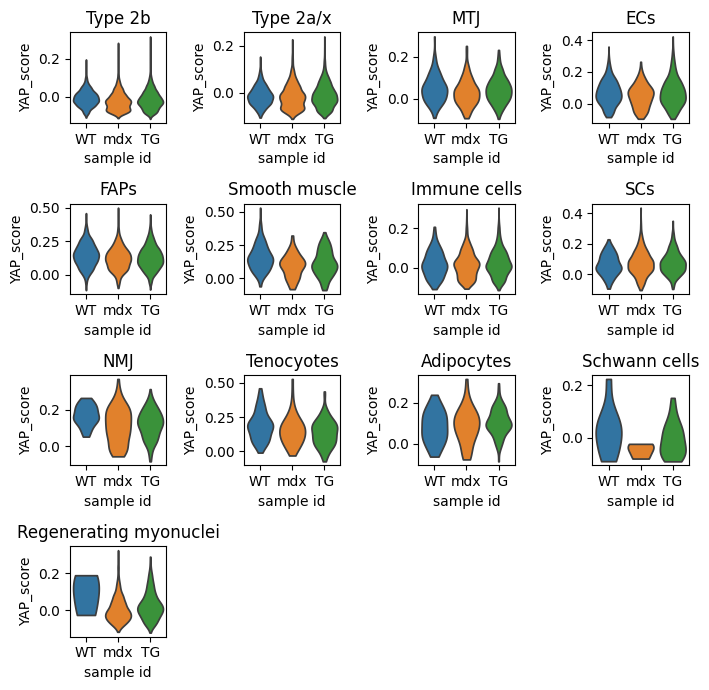

In [41]:
fig, axes = plt.subplots(4, 4, figsize=(7, 7))
axes_flat = axes.flatten()

for i, cell in enumerate(cell_labels):
    ax = axes_flat[i]
    sc.pl.violin(
        all_data[all_data.obs["cell_type"] == cell],
        keys="YAP_score",
        groupby="sample_id",
        stripplot=False,
        show=False,
        size=0,
        ax=ax
    )
    # ax.set_ylim(0, 1)
    ax.set_title(cell)  # optional, label each panel

# Hide any unused axes if len(cell_labels) < 12
for ax in axes_flat[len(cell_labels):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()